# Vinculum 07 · Optimized portfolios (borg-queen)

Notebook 06's combined book is equal weighted within quintiles: it takes sector bets of up to
20%, turns over 11 times a year and loses money after costs from $1 billion. Here the same
score feeds `borg-queen`'s optimizer, which trades expected return against forecast risk and
the cost unimatrix-zero will charge:

- **expected return** (Grinold): IC × score z-score × specific volatility, IC 0.03 a month;
- **objective**: expected return − trading cost (half-spread, commission, square-root impact
  at the given AUM) − borrow;
- **limits**: net 0 and gross 2 (long-short), 8% forecast volatility a year, every sector's net
  weight within ±1%, predicted beta within ±0.05, size exposure within ±0.1, 2% per name,
  each trade at most 10% of average daily dollar volume;
- **holdings carried forward**: each month starts from last month's weights drifted with
  prices, so a trade happens only when its expected gain beats its cost.

1. the risk model and expected returns
2. one rebalance
3. the optimized book against the quintile books
4. capacity: $10 million to $1 billion
5. risk: forecast against realized, and what the book is exposed to
6. go / no-go
7. caveats

In [1]:
import matplotlib.pyplot as plt
import polars as pl
from borg_queen import Optimizer, Portfolio, RiskModel, alpha_from_score, bias_stat
from massive_subspace_stream import Store
from neural_processor import Processor, composite
from subspace_probe import style, timed
from unimatrix_zero import CostModel, Engine, quantile_weights
from vinculum import Vinculum

style()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_cols(16)
v, massive = Vinculum(), Store()
p, eng = Processor(vinculum=v, store=massive), Engine(vinculum=v, store=massive)
rm = RiskModel(processor=p, engine=eng)
START, TOP = "2012-01-01", 1000
VALUE = ["earnings_yield", "book_to_market", "fcf_yield", "ebitda_to_ev"]
QUALITY = ["roe", "gross_profitability", "cash_roa", "accruals"]
with timed("signal panel"):
    sig = p.panel([*VALUE, *QUALITY, "momentum_12_1"], start=START, top=TOP)
sig = composite(sig, VALUE, name="value", min_signals=2)
sig = composite(sig, QUALITY, name="quality", min_signals=2)
sig = composite(sig, ["momentum_12_1"], name="momentum")
sig = composite(sig, {"value": 1, "quality": 1, "momentum": 1}, name="combined", min_signals=2)
sig = sig.filter(pl.col("date") >= pl.date(2012, 12, 31))        # risk model forecasts start here
print(f"{sig.height:,} rows, {sig['date'].n_unique()} month ends")


def show(bt, label):
    s = bt.summary().filter(pl.col("series") == "net").row(0, named=True)
    g = bt.summary().filter(pl.col("series") == "gross").row(0, named=True)
    return {"portfolio": label, "gross_return": g["ann_return"], "net_return": s["ann_return"],
            "net_vol": s["ann_vol"], "net_sharpe": s["sharpe"], "max_drawdown": s["max_drawdown"],
            "turnover_per_year": s["turnover_per_year"], "cost_drag": s["cost_drag"], "beta": s.get("beta")}


def sector_bets(w):
    """Largest absolute net sector weight per date (no sector counts as "Other", as in the risk model)."""
    x = (w.select("date", "security_id", "weight")
         .join(sig.select("date", "security_id", "sector"), on=["date", "security_id"], how="left")
         .with_columns(pl.col("sector").fill_null("Other")))
    return (x.group_by("date", "sector").agg(pl.col("weight").sum())
            .group_by("date").agg(pl.col("weight").abs().max().alias("max_sector")).sort("date"))


def table(rows):
    return pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(3))

signal panel: 16.26 s
168,000 rows, 168 month ends


## 1 · Risk model and expected returns

The risk model (decision 0009) is built from the same universe: 21 factors (market, 12
sectors, 8 styles), daily factor returns, EWMA covariance with a regime adjustment, and
specific risk per stock. `queen build` writes it in about 30 seconds.

In [2]:
rm.status()

{'built_at': '2026-11-03T19:50:31',
 'start': '2011-01-01',
 'end': None,
 'first_month': '2011-01-31',
 'last_month': '2026-11-02',
 'days': 3962,
 'median_r2': 0.3284,
 'factors': ['market',
  'Consumer non-durables',
  'Consumer durables',
  'Manufacturing',
  'Energy',
  'Chemicals',
  'Business equipment',
  'Telecom',
  'Utilities',
  'Shops',
  'Healthcare',
  'Finance',
  'Other',
  'size',
  'value',
  'momentum',
  'volatility',
  'beta',
  'profitability',
  'leverage',
  'liquidity'],
 'settings': {'top': 1000,
  'hl_vol': 84,
  'hl_corr': 252,
  'hl_vra': 42,
  'hl_spec': 84,
  'min_obs': 42,
  'shrink': 0.3},
 'seconds': 28.2}

In [3]:
alpha = alpha_from_score(sig, "combined", rm)
last = alpha["date"].max()
a = alpha.filter(pl.col("date") == last)
print(f"{alpha.height:,} expected returns; on {last}: {a.height} names")
a.select(pl.col("alpha").mul(1e4).quantile(q).round(0).alias(f"p{int(q * 100)}_bp")
         for q in (0.01, 0.1, 0.5, 0.9, 0.99))

165,046 expected returns; on 2026-11-02: 964 names


p1_bp,p10_bp,p50_bp,p90_bp,p99_bp
f64,f64,f64,f64,f64
-110.0,-29.0,-2.0,33.0,103.0


Expected returns are in basis points a month: a name 1 standard deviation up the score with
30% specific volatility a year is expected to beat its factor-explained return by
0.03 × 8.7% ≈ 26 bp a month. Only the ranking and the relative size matter to the optimizer
under a volatility target; the level matters against costs (section 4 tests it).

## 2 · One rebalance

The last month end, from cash, with no AUM (spreads and commission only).

In [4]:
last_d = sig["date"].max()
mk = (eng.returns(a["security_id"].to_list(), last_d.replace(day=1), last_d)
      .group_by("security_id").agg(pl.all().sort_by("date").last()))
sol = Optimizer(rm, CostModel()).solve(a, last_d, None, mk)
{k: (round(x, 4) if isinstance(x, float) else x) for k, x in sol.info.items()}

{'date': datetime.date(2026, 11, 2),
 'model_date': datetime.date(2026, 11, 2),
 'status': 'optimal',
 'relaxed': 'none',
 'alpha': 0.0105,
 'vol': np.float64(0.08),
 'cost': 0.0006,
 'turnover': 2.0,
 'sold_outside': 0.0,
 'names': 280,
 'gross': 2.0,
 'beta': 0.0048,
 'seconds': 0.14}

In [5]:
w1 = sol.weights.with_columns(pl.lit(last_d).alias("date"))
rm.contributions(w1, last_d).with_columns(pl.col(pl.Float64).round(3)).sort("contribution", descending=True).head(12)

factor,exposure,factor_vol,contribution
str,f64,f64,f64
"""specific""",null,null,0.644
"""profitability""",1.402,0.023,0.153
"""value""",0.874,0.035,0.134
"""momentum""",0.247,0.12,0.077
"""leverage""",0.212,0.03,0.004
"""beta""",-0.053,0.137,0.003
"""Shops""",0.01,0.098,0.001
"""market""",-0.0,0.155,-0.0
"""Consumer non-durables""",-0.001,0.117,-0.0


About two thirds of the forecast risk is specific: the book holds 280 names at up to 2%. The
factor risk comes from what the score asks for (profitability, value, momentum); sectors, beta
and size are held near zero, and the 8% volatility target binds.

## 3 · Optimized against quintile books

Monthly rebalances from December 2012, default costs and no AUM, trading the day after the
signal. The quintile books are notebook 06's: as built, and sector neutral.

In [6]:
with timed("optimized book"):
    w_opt, diag = Portfolio(Optimizer(rm, CostModel())).build(alpha)
print(diag.group_by("status", "relaxed").len())
diag.select(pl.col("names").mean().round(0), pl.col("turnover").mean().round(2), pl.col("vol").mean().round(3),
            pl.col("seconds").mean().round(2))

optimized book: 25.04 s
shape: (1, 3)
┌─────────┬─────────┬─────┐
│ status  ┆ relaxed ┆ len │
│ ---     ┆ ---     ┆ --- │
│ str     ┆ str     ┆ u32 │
╞═════════╪═════════╪═════╡
│ optimal ┆ none    ┆ 167 │
└─────────┴─────────┴─────┘


names,turnover,vol,seconds
f64,f64,f64,f64
198.0,0.77,0.08,0.12


In [7]:
books = {"optimized": w_opt,
         "quintile": quantile_weights(sig, "combined", q=0.2),
         "quintile, sector neutral": quantile_weights(sig, "combined", q=0.2, sector_neutral=True)}
runs = {name: eng.run(w) for name, w in books.items()}
table([{**show(b, name), "max_sector": sector_bets(books[name])["max_sector"].max()} for name, b in runs.items()])

/var/folders/sg/dcpyn54938s77cp4knr5zw500000gn/T/ipykernel_4687/3956738126.py:4: UserWarning: 7 trades (1 securities) cost more than 100 bp per unit traded; worst: KNM (CIK:0001191141:KNM) 148 bp on 2014-03-03 (21-day dollar volume 41,379). A data error (wrong market cap or volume) or a position too large for the stock: see Backtest.cost_warnings.
  runs = {name: eng.run(w) for name, w in books.items()}


portfolio,gross_return,net_return,net_vol,net_sharpe,max_drawdown,turnover_per_year,cost_drag,beta,max_sector
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""optimized""",0.058,0.051,0.091,0.592,-0.207,9.375,0.007,0.003,0.01
"""quintile""",0.062,0.054,0.101,0.572,-0.163,11.209,0.009,-0.015,0.232
"""quintile, sector neutral""",0.05,0.042,0.082,0.541,-0.131,11.667,0.009,-0.01,0.0


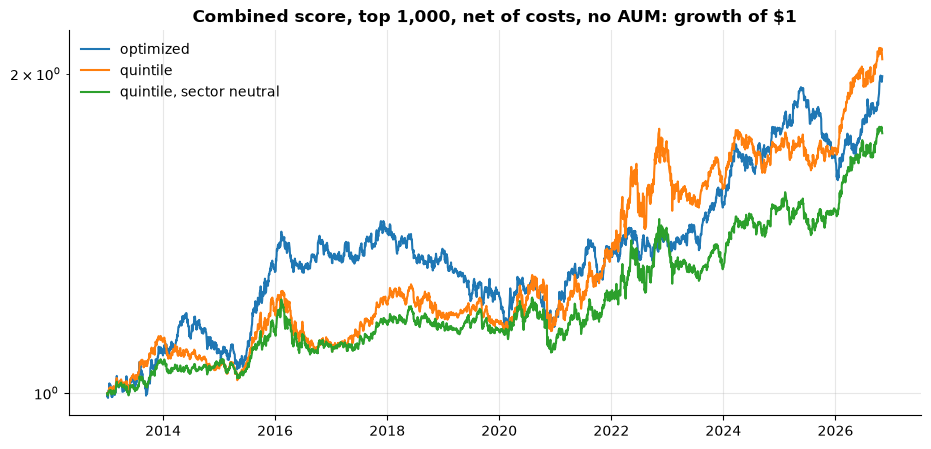

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
for name, b in runs.items():
    ax.plot(b.daily["date"], b.daily["nav"], label=name)
ax.set_yscale("log")
ax.set_title("Combined score, top 1,000, net of costs, no AUM: growth of $1")
ax.legend()
plt.show()

With no AUM the optimized book is about level with the quintile books: net Sharpe 0.59
against 0.57 (as built) and 0.54 (sector neutral), a little less turnover (9.4 against 11.2 a
year), and sector bets held at 1% instead of up to 23%. At this size the optimizer buys control
of the bets, not extra return.

## 4 · Capacity

Each book is run at four sizes with the same cost model in the optimizer and in the backtest:
square-root impact (daily volatility × √(trade / ADV)) plus the half-spread, and for the
optimized book a 10% participation limit. The quintile books cannot react to the AUM; the
optimizer trades less, and in more liquid names, as it grows.

In [9]:
rows, opt_runs, diags = [], {}, {}
with timed("capacity"):
    for aum in [None, 1e7, 1e8, 1e9]:
        cm = CostModel(aum=aum)
        w, dg = Portfolio(Optimizer(rm, cm)).build(alpha)
        opt_runs[aum], diags[aum] = (w, eng.run(w, costs=cm)), dg
        for name, wb in [("optimized", w), *[(k, books[k]) for k in ("quintile", "quintile, sector neutral")]]:
            b = opt_runs[aum][1] if name == "optimized" else eng.run(wb, costs=cm)
            r = show(b, name)
            rows.append({"aum_musd": aum / 1e6 if aum else 0.0, "portfolio": name,
                         **{k: r[k] for k in ("net_return", "net_vol", "net_sharpe", "turnover_per_year", "cost_drag")}})
cap = table(rows)
cap.pivot(on="portfolio", index="aum_musd", values="net_sharpe")

/var/folders/sg/dcpyn54938s77cp4knr5zw500000gn/T/ipykernel_4687/1564585525.py:8: UserWarning: 7 trades (1 securities) cost more than 100 bp per unit traded; worst: KNM (CIK:0001191141:KNM) 148 bp on 2014-03-03 (21-day dollar volume 41,379). A data error (wrong market cap or volume) or a position too large for the stock: see Backtest.cost_warnings.
  b = opt_runs[aum][1] if name == "optimized" else eng.run(wb, costs=cm)


/var/folders/sg/dcpyn54938s77cp4knr5zw500000gn/T/ipykernel_4687/1564585525.py:6: UserWarning: 4 trades (4 securities) cost more than 100 bp per unit traded; worst: None (BBG00PK930R9) 213 bp on 2022-03-01 (21-day dollar volume 1,124,778). A data error (wrong market cap or volume) or a position too large for the stock: see Backtest.cost_warnings.
  opt_runs[aum], diags[aum] = (w, eng.run(w, costs=cm)), dg


/var/folders/sg/dcpyn54938s77cp4knr5zw500000gn/T/ipykernel_4687/1564585525.py:8: UserWarning: 85 trades (24 securities) cost more than 100 bp per unit traded; worst: WINS (CIK:0001681941:WINS) 451 bp on 2017-02-01 (21-day dollar volume 869,856). A data error (wrong market cap or volume) or a position too large for the stock: see Backtest.cost_warnings.
  b = opt_runs[aum][1] if name == "optimized" else eng.run(wb, costs=cm)


/var/folders/sg/dcpyn54938s77cp4knr5zw500000gn/T/ipykernel_4687/1564585525.py:8: UserWarning: 80 trades (20 securities) cost more than 100 bp per unit traded; worst: WINS (CIK:0001681941:WINS) 451 bp on 2017-02-01 (21-day dollar volume 869,856). A data error (wrong market cap or volume) or a position too large for the stock: see Backtest.cost_warnings.
  b = opt_runs[aum][1] if name == "optimized" else eng.run(wb, costs=cm)


/var/folders/sg/dcpyn54938s77cp4knr5zw500000gn/T/ipykernel_4687/1564585525.py:6: UserWarning: 28 trades (16 securities) cost more than 100 bp per unit traded; worst: None (BBG00PK930R9) 335 bp on 2022-03-01 (21-day dollar volume 1,124,778). A data error (wrong market cap or volume) or a position too large for the stock: see Backtest.cost_warnings.
  opt_runs[aum], diags[aum] = (w, eng.run(w, costs=cm)), dg


/var/folders/sg/dcpyn54938s77cp4knr5zw500000gn/T/ipykernel_4687/1564585525.py:8: UserWarning: 498 trades (118 securities) cost more than 100 bp per unit traded; worst: WINS (CIK:0001681941:WINS) 1,316 bp on 2017-02-01 (21-day dollar volume 869,856). A data error (wrong market cap or volume) or a position too large for the stock: see Backtest.cost_warnings.
  b = opt_runs[aum][1] if name == "optimized" else eng.run(wb, costs=cm)


... (2 outputs left out)

/var/folders/sg/dcpyn54938s77cp4knr5zw500000gn/T/ipykernel_4687/1564585525.py:8: UserWarning: 3617 trades (965 securities) cost more than 100 bp per unit traded; worst: WINS (CIK:0001681941:WINS) 3,747 bp on 2017-02-01 (21-day dollar volume 869,856). A data error (wrong market cap or volume) or a position too large for the stock: see Backtest.cost_warnings.
  b = opt_runs[aum][1] if name == "optimized" else eng.run(wb, costs=cm)


capacity: 324.32 s


/var/folders/sg/dcpyn54938s77cp4knr5zw500000gn/T/ipykernel_4687/1564585525.py:8: UserWarning: 3460 trades (911 securities) cost more than 100 bp per unit traded; worst: WINS (CIK:0001681941:WINS) 3,733 bp on 2017-02-01 (21-day dollar volume 869,856). A data error (wrong market cap or volume) or a position too large for the stock: see Backtest.cost_warnings.
  b = opt_runs[aum][1] if name == "optimized" else eng.run(wb, costs=cm)


aum_musd,optimized,quintile,"quintile, sector neutral"
f64,f64,f64,f64
0.0,0.592,0.572,0.541
10.0,0.495,0.501,0.454
100.0,0.41,0.359,0.277
1000.0,0.398,-0.013,-0.179


In [10]:
cap

aum_musd,portfolio,net_return,net_vol,net_sharpe,turnover_per_year,cost_drag
f64,str,f64,f64,f64,f64,f64
0.0,"""optimized""",0.051,0.091,0.592,9.375,0.007
0.0,"""quintile""",0.054,0.101,0.572,11.209,0.009
0.0,"""quintile, sector neutral""",0.042,0.082,0.541,11.667,0.009
10.0,"""optimized""",0.041,0.09,0.495,6.751,0.011
10.0,"""quintile""",0.046,0.101,0.501,11.209,0.016
10.0,"""quintile, sector neutral""",0.034,0.082,0.454,11.667,0.016
100.0,"""optimized""",0.033,0.088,0.41,4.869,0.013
100.0,"""quintile""",0.032,0.101,0.359,11.209,0.031
100.0,"""quintile, sector neutral""",0.02,0.082,0.277,11.667,0.031


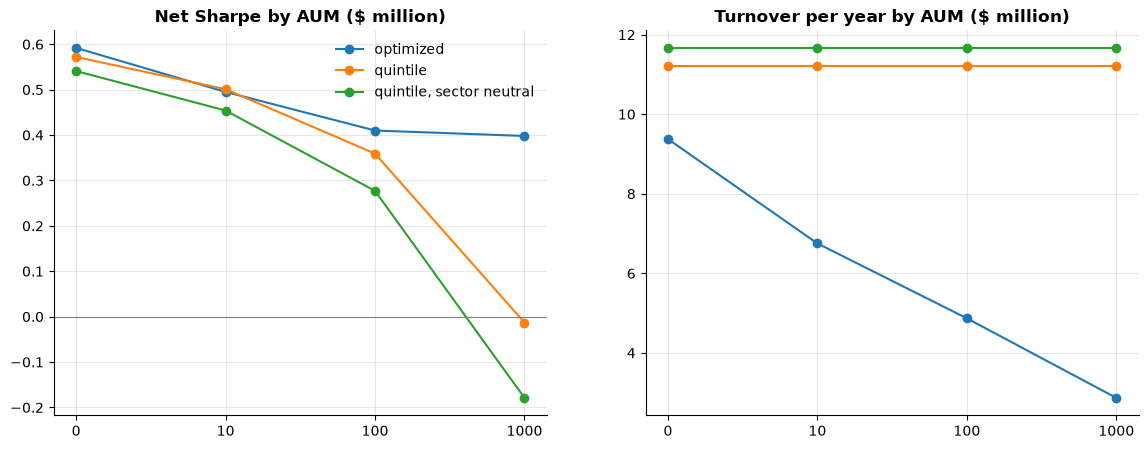

aum_musd,names,turnover_per_rebalance,relaxed_rebalances
f64,f64,f64,i64
0.0,197.84,0.77,0
10.0,257.32,0.56,0
100.0,353.31,0.4,0
1000.0,563.96,0.24,0


In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name in books:
    c = cap.filter(pl.col("portfolio") == name)
    x = [str(int(a)) if a else "0" for a in c["aum_musd"]]
    ax1.plot(x, c["net_sharpe"], marker="o", label=name)
    ax2.plot(x, c["turnover_per_year"], marker="o", label=name)
ax1.axhline(0, color="grey", lw=0.8)
ax1.set_title("Net Sharpe by AUM ($ million)")
ax2.set_title("Turnover per year by AUM ($ million)")
ax1.legend()
plt.show()
pl.DataFrame([{"aum_musd": a / 1e6 if a else 0.0, "names": d["names"].mean(), "turnover_per_rebalance": d["turnover"].mean(),
               "relaxed_rebalances": int((d["relaxed"] != "none").sum())} for a, d in diags.items()]).with_columns(
    pl.col(pl.Float64).round(2))

The difference is capacity. As AUM grows the optimizer trades less (9.4 → 2.9 times a
year) and spreads over more names (198 → 564) so that each trade stays small against volume.
Its cost drag stays near 1.2% a year, while the quintile books pay 3.1% at $100 million and
6.9% at $1 billion. At $1 billion the optimized book still earns 3.0% net (Sharpe 0.40); both
quintile books lose money. The price is a smaller share of the signal captured: net return
plus costs falls from 5.8% with no AUM to 4.2% at $1 billion, as positions are kept after the
score has moved on. No rebalance needed a relaxed limit at any size.

## 5 · Risk: forecast against realized, and exposures

The bias statistic compares each month's realized daily returns with that month's forecast
(1 is right; 0.8-1.2 passes). Sector bets are the largest absolute net sector weight at each
rebalance.

In [12]:
rows = []
for name, w in [("optimized, $100M", opt_runs[1e8][0]), *[(k, books[k]) for k in ("quintile", "quintile, sector neutral")]]:
    b = rm.bias(w.select("date", "security_id", "weight"))
    sb = sector_bets(w)["max_sector"]
    rows.append({"portfolio": name, "bias": bias_stat(b), "forecast_vol": b["forecast_vol"].mean(),
                 "realized_vol": b["realized_vol"].mean(), "max_sector": sb.max(), "median_sector": sb.median()})
table(rows)

portfolio,bias,forecast_vol,realized_vol,max_sector,median_sector
str,f64,f64,f64,f64,f64
"""optimized, $100M""",1.131,0.077,0.085,0.01,0.01
"""quintile""",1.057,0.091,0.09,0.232,0.132
"""quintile, sector neutral""",1.021,0.078,0.074,0.0,0.0


In [13]:
att = rm.attribute(opt_runs[1e8][0].select("date", "security_id", "weight"))
factors = [c for c in att.columns if c not in ("date", "total", "uncovered")]
(att.select(*[(pl.col(f).sum() / (att.height / 252)).alias(f) for f in ["total", *factors]])
 .unpivot(variable_name="source", value_name="return_per_year").with_columns(pl.col("return_per_year").round(4))
 .sort(pl.col("return_per_year").abs(), descending=True).head(12))

source,return_per_year
str,f64
"""total""",0.0551
"""momentum""",0.0276
"""profitability""",0.0165
"""value""",0.0149
"""specific""",-0.007
"""liquidity""",0.002
"""volatility""",0.0006
"""Telecom""",-0.0005
"""Consumer durables""",0.0004


Realized volatility was 8.5% against a 7.7% average forecast (bias 1.13), a little more
under-forecast than the quintile books (1.06 and 1.02). An optimizer leans toward bets whose
risk the model under-states, so this is expected; in practice the 8% target delivers about
8.5-9%. Sector bets sit at the 1% limit at every rebalance.

The return came from the intended factors: momentum 2.8% a year, profitability 1.7% and value
1.5%, with specific returns costing 0.7% (attribution holds weights constant between
rebalances and is before costs).

## 6 · Go / no-go

Criteria set before the run: net Sharpe at $100 million ≥ 0.30, a positive net return at
$1 billion, and no sector bet beyond 1%.

In [14]:
o = cap.filter(pl.col("portfolio") == "optimized")
s100 = o.filter(pl.col("aum_musd") == 100)["net_sharpe"].item()
r1b = o.filter(pl.col("aum_musd") == 1000)["net_return"].item()
sec = sector_bets(opt_runs[1e8][0])["max_sector"].max()
pl.DataFrame({"criterion": ["net Sharpe at $100M >= 0.30", "net return at $1B > 0", "max sector bet <= 1%"],
              "value": [round(s100, 3), round(r1b, 4), round(sec, 4)],
              "pass": [s100 >= 0.30, r1b > 0, sec <= 0.01 + 1e-5]})   # solver tolerance

criterion,value,pass
str,f64,bool
"""net Sharpe at $100M >= 0.30""",0.41,true
"""net return at $1B > 0""",0.03,true
"""max sector bet <= 1%""",0.01,true


All three pass with the default settings; nothing was tuned to them. The sector limit
binds at 1.00% (within solver tolerance). The margin at $100 million is 0.11 of Sharpe, and a
Sharpe ratio measured over 14 years has a standard error near 0.27, so the firm result is the
capacity gap at $1 billion rather than the level at any one size.

## 7 · Caveats

- **Same data as notebook 06**: one period (2013-2026) and one universe (the top 1,000).
  The IC of 0.03 is an assumption, not fitted here; a lower IC makes the optimizer trade less.
- **The score matters more than the optimizer at small size.** A variant of the combined score
  (value from book/market, earnings, cash-flow and FCF yield; quality from gross profitability,
  ROE and accruals) gave the optimized book a net Sharpe of 0.83 with no AUM and 0.58 at
  $100 million, against 0.64 and 0.42 for its quintile book: higher levels, the same pattern.
- **Costs are models**, the same in the optimizer and the backtest: the optimizer is rewarded
  for avoiding exactly the costs the backtest charges. Real costs that the model misses
  (borrow recalls, squeezes, crowded exits) would hurt the optimized book as much.
- **The sector limit binds on the optimizer's weights**; drift between rebalances can move a
  sector past 1% before the next one.
- **Risk is under-forecast in regime changes** (2020-21, decision 0009), so the 8% target is
  exceeded in such years.
- **Monthly rebalances only**; the optimizer itself takes about 0.1 s per date, so daily or
  weekly rebalancing is possible.